## ✳**Primeira etapa do pré processamento** :

obs:
lembrar de pôr o repositório do projeto no /Mydrive‼️‼️

In [70]:
!pip install mne -q

In [71]:
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
import mne
#importando do drive

from google.colab import drive
drive.mount('/content/drive', force_remount=True)

Mounted at /content/drive



o dicionario subjects define o mapa dos 5 conjuntos (nome da pasta + descrição clínica). no final, confere que as 5 pastas existem e têm 100 arquivos `.txt` cada.

In [72]:
path = Path('/content/drive/MyDrive/Projet Thématique/raw')

freq = 173.61
n_samples = 4096

subjects = {
    "A": ("A (Z)", "saudável, olhos abertos"),
    "B": ("B (O)", "saudável, olhos fechados"),
    "C": ("C (N)", "interictal, hemisfério oposto"),
    "D": ("D (F)", "interictal, zona epileptogênica"),
    "E": ("E (S)", "ictal / crise"),
}

print("raw existe?", path.exists())
for label, (subpasta, _) in subjects.items():
    pasta = path / subpasta
    if pasta.exists():
        n_txt = sum(1 for p in pasta.iterdir() if p.suffix.lower() == ".txt")
        print(f"{subpasta}: {n_txt} arquivos .txt")
    else:
        print(f"{subpasta}: PASTA NÃO ENCONTRADA")

raw existe? True
A (Z): 100 arquivos .txt
B (O): 100 arquivos .txt
C (N): 100 arquivos .txt
D (F): 100 arquivos .txt
E (S): 100 arquivos .txt


lê os 500 arquivos `.txt` e devolve três arrays: `sinais` (que é a matriz dos dados EEG 500 arquivos com 4096 linhas/pontos cada), `rotulos` (500,) com as letras A–E, e `ids` com o nome de cada arquivo

In [73]:
def carregar_bonn(base_dir=path, sets=subjects, n_samples=n_samples):
    sinais, rotulos, ids = [], [], []
    for label, (subpasta, _desc) in sets.items():
        pasta = base_dir / subpasta
        arquivos = sorted(p for p in pasta.iterdir() if p.suffix.lower() == ".txt")
        for arq in arquivos:
            sig = np.loadtxt(arq)[:n_samples]
            sinais.append(sig)
            rotulos.append(label)
            ids.append(arq.name)
    return np.vstack(sinais), np.array(rotulos), np.array(ids)

sinais, rotulos, ids = carregar_bonn()

print("Sinais:", sinais.shape, "Rótulos:", rotulos.shape)
print("Por conjunto:", {str(k): int(v) for k, v in zip(*np.unique(rotulos, return_counts=True))})

Sinais: (500, 4096) Rótulos: (500,)
Por conjunto: {'A': 100, 'B': 100, 'C': 100, 'D': 100, 'E': 100}


estrutura do MNE com os 500 sinais, cada um associado ao seu conjunto. o objeto epochs guarda o conjunto de segmentos e seus respectivos rótulos. É útil salvar no formato aceito pelo MNE pra quando formos importar os dados com essa biblioteca.

In [74]:
info = mne.create_info(ch_names=["EEG"], sfreq=freq, ch_types="eeg")

dados_mne = sinais[:, np.newaxis, :] * 1e-6 # (n_sinais, n_canais, n_amostras) e unidade em micro volts

event_id = {label: i + 1 for i, label in enumerate(subjects)}
codigos = np.array([event_id[r] for r in rotulos])
events = np.column_stack([
    np.arange(len(sinais)) * n_samples,
    np.zeros(len(sinais), dtype=int),
    codigos,
])
epochs = mne.EpochsArray(dados_mne, info, events=events, event_id=event_id, tmin=0, verbose=False)
print(epochs)

<EpochsArray | 500 events (all good), 0 – 23.587 s (baseline off), ~15.6 MiB, data loaded,
 'A': 100
 'B': 100
 'C': 100
 'D': 100
 'E': 100>


### Sinais no tempo
Plota um sinal de cada conjunto, na mesma escala, para compará-los visualmente.

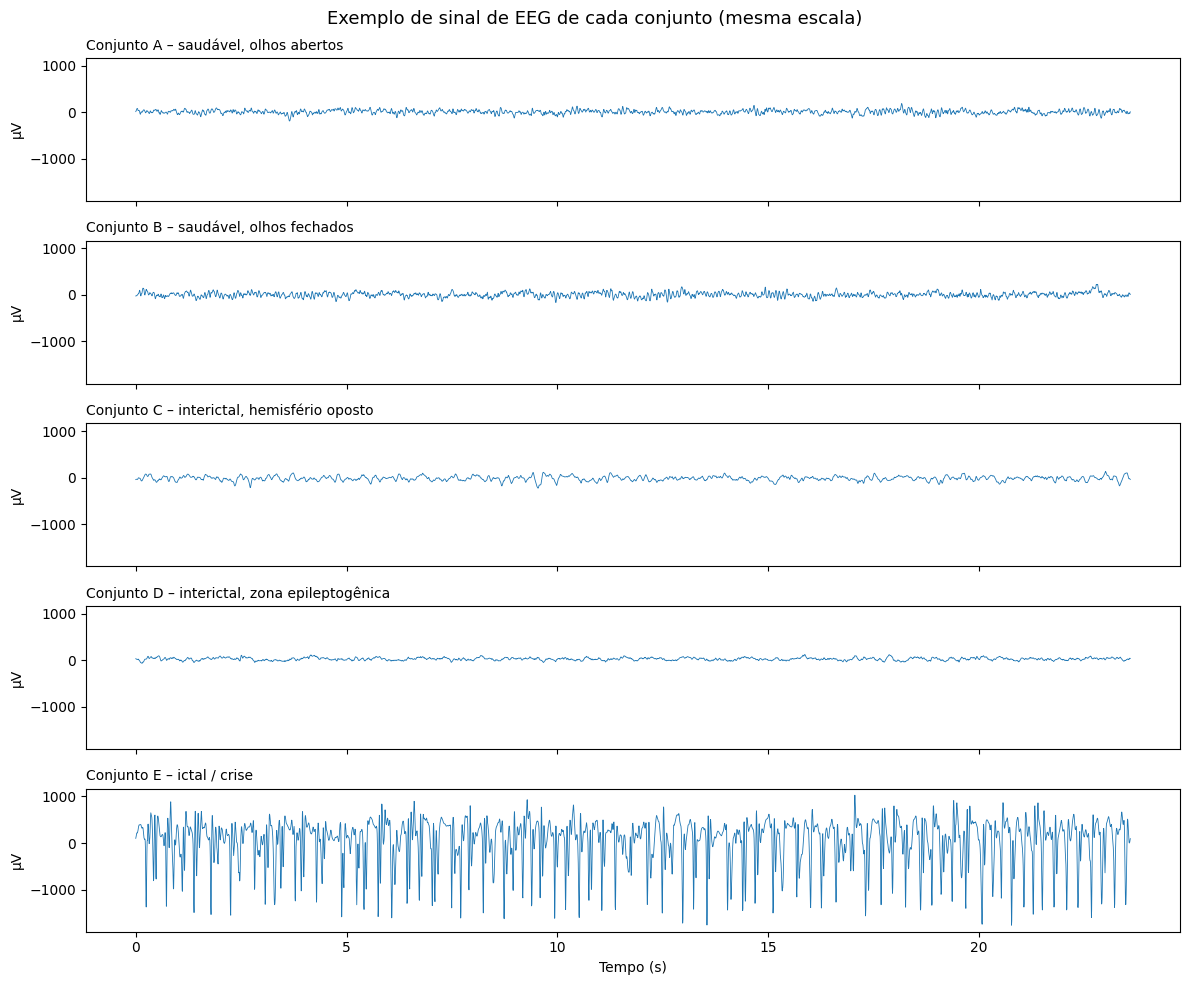

In [75]:
# pasta para salvar as figuras do relatório (dentro de Projet Thématique)
pasta_fig = path.parent / "figuras"
pasta_fig.mkdir(exist_ok=True)

t = np.arange(n_samples) / freq
fig, axes = plt.subplots(5, 1, figsize=(12, 10), sharex=True, sharey=True)

for ax, (label, (_, desc)) in zip(axes, subjects.items()):
    sinal = sinais[rotulos == label][0]   # primeiro sinal do conjunto
    ax.plot(t, sinal, lw=0.6)
    ax.set_title(f"Conjunto {label} – {desc}", fontsize=10, loc="left")
    ax.set_ylabel("µV")

axes[-1].set_xlabel("Tempo (s)")
fig.suptitle("Exemplo de sinal de EEG de cada conjunto (mesma escala)", fontsize=13)
plt.tight_layout()
plt.savefig(pasta_fig / "01_sinais_exemplo.png", dpi=300)
plt.show()

### Amplitude por conjunto
Resume a amplitude de cada sinal pelo desvio-padrão e compara a distribuição entre os conjuntos (escala log). Justifica a necessidade de **normalização** no pré-processamento, já que as escalas diferem em ordens de grandeza.

    mean    std
A   40.7    8.3
B   61.1   18.2
C   50.8   19.3
D   65.6   57.8
E  306.5  147.9


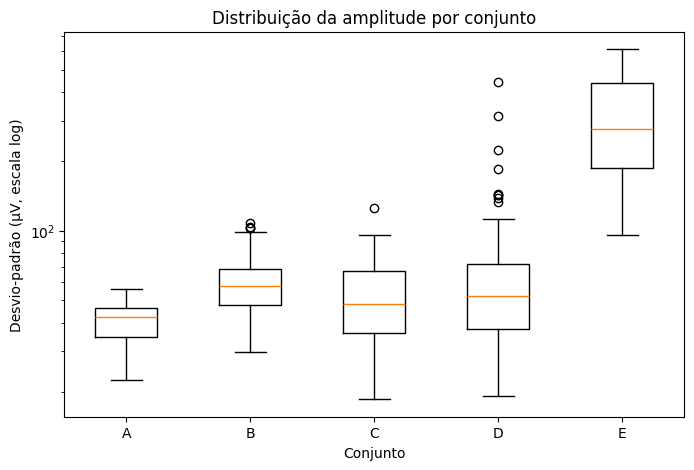

In [76]:
import pandas as pd

desvio = sinais.std(axis=1)

print(pd.Series(desvio).groupby(rotulos).agg(["mean", "std"]).round(1))

plt.figure(figsize=(8, 5))
plt.boxplot([desvio[rotulos == label] for label in subjects], tick_labels=list(subjects))
plt.yscale("log")
plt.xlabel("Conjunto")
plt.ylabel("Desvio-padrão (µV, escala log)")
plt.title("Distribuição da amplitude por conjunto")
plt.savefig(pasta_fig / "02_amplitude_boxplot.png", dpi=300)
plt.show()

Investigação dos outliers de D: segmento de maior amplitude (é um zoom nele em relação ao primeiro gráfico em função do tempo)


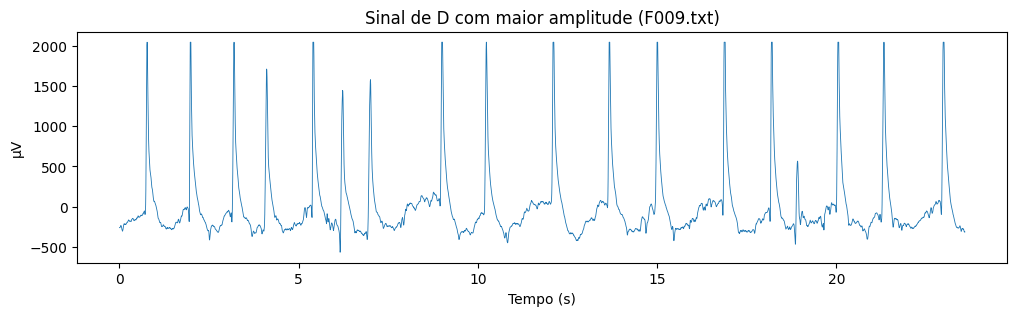

In [77]:
idx_max_D = np.argmax(np.where(rotulos == "D", desvio, 0))
plt.figure(figsize=(12, 3))
plt.plot(t, sinais[idx_max_D], lw=0.6)
plt.title(f"Sinal de D com maior amplitude ({ids[idx_max_D]})")
plt.xlabel("Tempo (s)"); plt.ylabel("µV")
plt.show()

### Espectro médio
Calcula a densidade espectral de potência (método de Welch) e mostra o espectro médio de cada conjunto. A linha em 40 Hz marca o corte do passa-baixa a ser aplicado (gráfico bom para compararmos depois da aplicação do filtro)

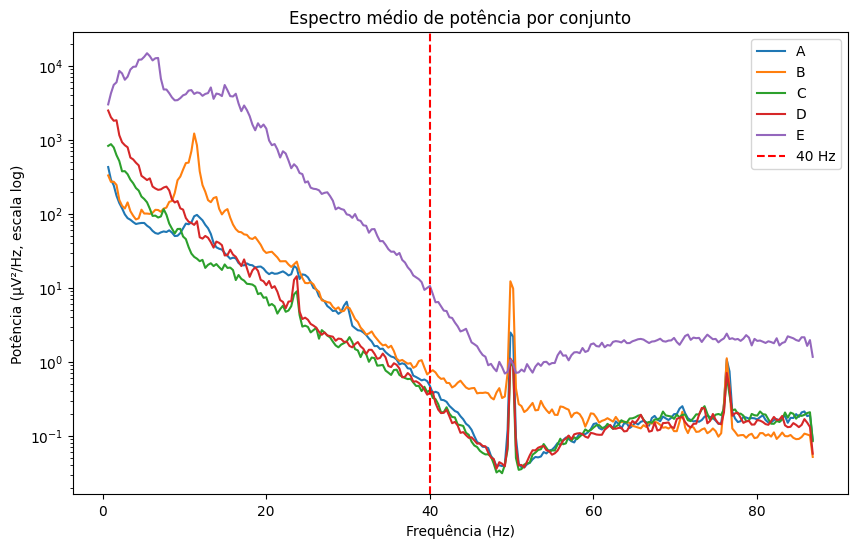

In [78]:
psd = epochs.compute_psd(method="welch", fmin=0.5, fmax=freq / 2, n_fft=512, verbose=False)
P, freqs = psd.get_data(return_freqs=True)
P = P[:, 0, :] * 1e12      # remove o eixo do canal e converte para µV²/Hz

plt.figure(figsize=(10, 6))
for label in subjects:
    plt.semilogy(freqs, P[rotulos == label].mean(axis=0), label=label)
plt.axvline(40, color="red", ls="--", label="40 Hz")
plt.xlabel("Frequência (Hz)")
plt.ylabel("Potência (µV²/Hz, escala log)")
plt.title("Espectro médio de potência por conjunto")
plt.legend()
plt.savefig(pasta_fig / "04_espectro_medio.png", dpi=300)
plt.show()

## ✳**Segunda etapa do pré processamento** :

Filtragem e divisão treino/teste



In [79]:
from scipy.signal import butter, filtfilt, freqz, welch, correlate, correlation_lags
from sklearn.model_selection import train_test_split, StratifiedKFold
import pandas as pd

SEED = 42   # semente única do grupo: todo mundo usa exatamente a mesma divisão

### Filtro passa-baixas de 40 Hz

Butterworth de ordem 4, corte em 40 Hz (fs = 173,61 Hz → Nyquist = 86,8 Hz):


In [80]:
def filtro_passa_baixas(sinais, fc=40.0, fs=freq, ordem=4):
    # Butterworth passa-baixas + filtfilt (fase zero), aplicado linha a linha (um sinal por linha)
    b, a = butter(ordem, fc, btype="low", fs=fs)   # passando fs, o scipy já normaliza pela frequência de Nyquist
    sinais_filtrados = filtfilt(b, a, sinais, axis=1)
    return sinais_filtrados, b, a


sinais_filtrados, b, a = filtro_passa_baixas(sinais)
print("sinais_filtrados:", sinais_filtrados.shape)

sinais_filtrados: (500, 4096)


### Verificação da filtragem

**1) Resposta em frequência do filtro.** Como o `filtfilt` passa o filtro duas vezes, o ganho efetivo é |H(f)|².

ganho em 20 Hz:    -0.0 dB
ganho em 30 Hz:    -0.4 dB
ganho em 40 Hz:    -6.0 dB
ganho em 50 Hz:   -25.8 dB
ganho em 60 Hz:   -53.1 dB
ganho em 80 Hz:  -153.8 dB


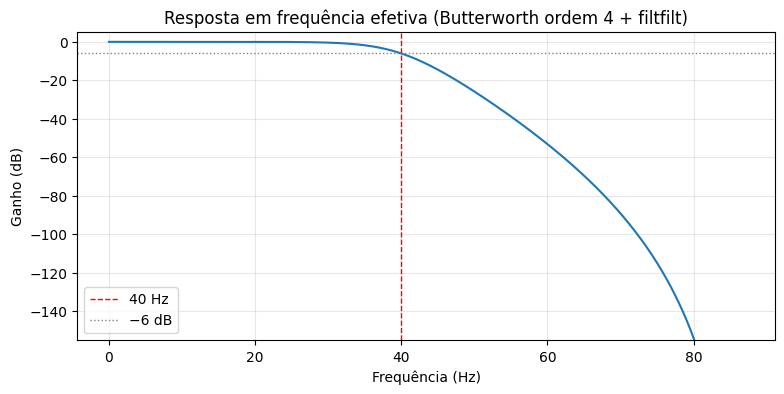

In [81]:
f_h, h = freqz(b, a, worN=4096, fs=freq)
ganho_db = 20 * np.log10(np.maximum(np.abs(h) ** 2, 1e-12))   # |H|² por causa do filtfilt

for f0 in [20, 30, 40, 50, 60, 80]:
    print(f"ganho em {f0:>2} Hz: {np.interp(f0, f_h, ganho_db):7.1f} dB")

plt.figure(figsize=(9, 4))
plt.plot(f_h, ganho_db, lw=1.5)
plt.axvline(40, color="red", ls="--", lw=1, label="40 Hz")
plt.axhline(-6, color="gray", ls=":", lw=1, label="−6 dB")
plt.ylim(-155, 5)
plt.xlabel("Frequência (Hz)")
plt.ylabel("Ganho (dB)")
plt.title("Resposta em frequência efetiva (Butterworth ordem 4 + filtfilt)")
plt.legend()
plt.grid(alpha=0.3)
plt.savefig(pasta_fig / "06_resposta_filtro.png", dpi=300)
plt.show()

**2) Espectro antes × depois**, médio por conjunto (Welch com janelas de 512 pontos).

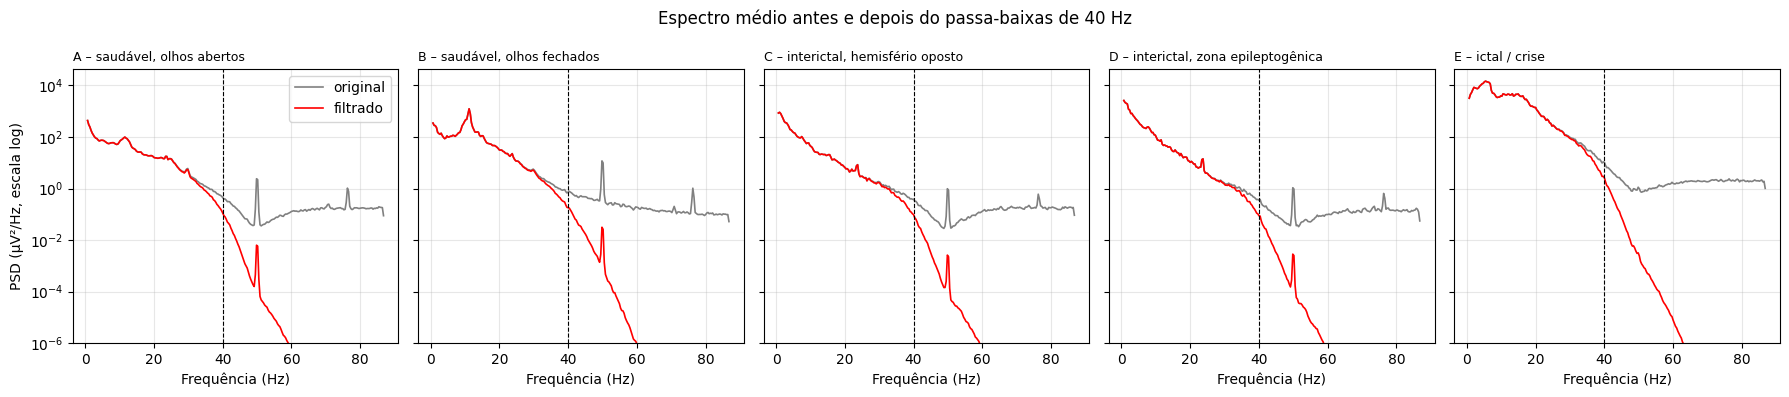

In [82]:
f, P_orig = welch(sinais, fs=freq, nperseg=512, axis=1)
_, P_filt = welch(sinais_filtrados, fs=freq, nperseg=512, axis=1)
mostrar = f >= 0.5   # mesma faixa do gráfico da etapa 1

fig, axes = plt.subplots(1, 5, figsize=(18, 4), sharey=True)
for ax, (label, (_, desc)) in zip(axes, subjects.items()):
    m = rotulos == label
    ax.semilogy(f[mostrar], P_orig[m].mean(axis=0)[mostrar], color="gray", lw=1.2, label="original")
    ax.semilogy(f[mostrar], P_filt[m].mean(axis=0)[mostrar], color="red", lw=1.2, label="filtrado")
    ax.axvline(40, color="black", ls="--", lw=0.8)
    ax.set_title(f"{label} – {desc}", fontsize=9, loc="left")
    ax.set_xlabel("Frequência (Hz)")
    ax.grid(alpha=0.3)
topo = max(P_orig[rotulos == label].mean(axis=0)[mostrar].max() for label in subjects)
axes[0].set_ylim(1e-6, 3 * topo)   # eixo y compartilhado pelos 5 painéis
axes[0].set_ylabel("PSD (µV²/Hz, escala log)")
axes[0].legend()
fig.suptitle("Espectro médio antes e depois do passa-baixas de 40 Hz", fontsize=12)
plt.tight_layout()
plt.savefig(pasta_fig / "07_espectro_antes_depois.png", dpi=300)
plt.show()

**3) Verificação numérica**, sinal a sinal e depois média por conjunto: quanto da potência está acima de 40 Hz antes/depois, quanto a faixa de rejeição (50–86 Hz) foi atenuada e quanto da banda útil (0,5–30 Hz) foi preservada.

In [83]:
df_f = f[1] - f[0]

def potencia(P, fmin, fmax):
    m = (f >= fmin) & (f < fmax)
    return P[:, m].sum(axis=1) * df_f

nyq = freq / 2
tot_orig, tot_filt = potencia(P_orig, 0.5, nyq), potencia(P_filt, 0.5, nyq)
acima_orig, acima_filt = potencia(P_orig, 40, nyq), potencia(P_filt, 40, nyq)
rej_orig, rej_filt = potencia(P_orig, 50, nyq), potencia(P_filt, 50, nyq)
util_orig, util_filt = potencia(P_orig, 0.5, 30), potencia(P_filt, 0.5, 30)

tabela = pd.DataFrame({
    "% pot. > 40 Hz (original)": 100 * acima_orig / tot_orig,
    "% pot. > 40 Hz (filtrado)": 100 * acima_filt / tot_filt,
    "ganho 50–86 Hz (dB)": 10 * np.log10(rej_filt / rej_orig),
    "pot. 0,5–30 Hz preservada (%)": 100 * util_filt / util_orig,
}).groupby(rotulos).mean().round(2)
print(tabela.to_string())

assert np.all(util_filt / util_orig > 0.95), "o filtro está distorcendo a banda útil (0,5–30 Hz)"
assert np.all(rej_filt < rej_orig), "o filtro não reduziu a potência acima de 50 Hz"
print("\nOK: banda útil preservada (> 95 %) e faixa de rejeição atenuada em todos os 500 sinais")

   % pot. > 40 Hz (original)  % pot. > 40 Hz (filtrado)  ganho 50–86 Hz (dB)  pot. 0,5–30 Hz preservada (%)
A                       0.60                       0.01               -33.22                          99.87
B                       0.56                       0.01               -30.69                          99.92
C                       0.25                       0.01               -36.35                          99.98
D                       0.22                       0.00               -35.66                          99.98
E                       0.08                       0.00               -42.40                          99.95

OK: banda útil preservada (> 95 %) e faixa de rejeição atenuada em todos os 500 sinais


**4) Fase zero e efeito no tempo.** A correlação cruzada entre original e filtrado tem o pico no atraso 0 em todos os 500 sinais, ou seja, o `filtfilt` não desloca o sinal no tempo. No gráfico, o sinal com mais conteúdo acima de 40 Hz: em cima as duas versões sobrepostas e, embaixo, o que o filtro removeu (original − filtrado).

atrasos encontrados (amostras): [0]


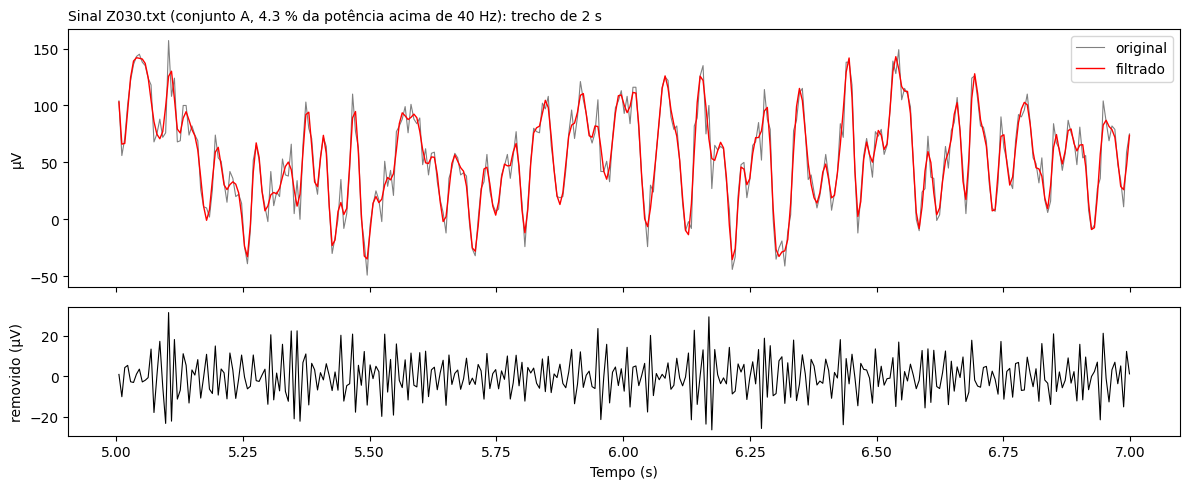

In [84]:
def atraso_amostras(x, y):
    # atraso de y em relação a x, pelo pico da correlação cruzada
    x, y = x - x.mean(), y - y.mean()
    c = correlate(y, x, mode="full", method="fft")
    return correlation_lags(len(y), len(x), mode="full")[np.argmax(c)]

atrasos = np.array([atraso_amostras(sinais[k], sinais_filtrados[k]) for k in range(len(sinais))])
print("atrasos encontrados (amostras):", np.unique(atrasos))
assert np.all(atrasos == 0), "o filtro deslocou algum sinal no tempo"

i = np.argmax(acima_orig / tot_orig)   # sinal com maior fração de potência acima de 40 Hz
trecho = (t >= 5) & (t < 7)

fig, axes = plt.subplots(2, 1, figsize=(12, 5), sharex=True, gridspec_kw={"height_ratios": [2, 1]})
axes[0].plot(t[trecho], sinais[i, trecho], color="gray", lw=0.8, label="original")
axes[0].plot(t[trecho], sinais_filtrados[i, trecho], color="red", lw=1.0, label="filtrado")
axes[0].set_ylabel("µV")
axes[0].legend(loc="upper right")
axes[0].set_title(f"Sinal {ids[i]} (conjunto {rotulos[i]}, {100 * acima_orig[i] / tot_orig[i]:.1f} % da potência acima de 40 Hz): trecho de 2 s",
                  fontsize=10, loc="left")
axes[1].plot(t[trecho], sinais[i, trecho] - sinais_filtrados[i, trecho], color="black", lw=0.8)
axes[1].set_ylabel("removido (µV)")
axes[1].set_xlabel("Tempo (s)")
plt.tight_layout()
plt.savefig(pasta_fig / "08_tempo_antes_depois.png", dpi=300)
plt.show()

### Estratégia anti-leakage do grupo

*Leakage* (vazamento) = informação do teste chegando ao treino, o que infla a acurácia. Regras que **todas as etapas** seguem:

1. **A unidade de divisão é o sinal inteiro** (um arquivo `.txt`, 23,6 s). A divisão treino/teste é feita nos 500 índices **antes do janelamento** (etapa 3), e toda janela herda o lado (treino ou teste) do sinal de onde saiu. Janelas do mesmo sinal são muito parecidas entre si (e, com sobreposição, compartilham amostras): se a divisão fosse feita depois do janelamento, o modelo reconheceria o sinal em vez de aprender a classe.
2. **Estratificação pelo conjunto A–E** (80 sinais de cada conjunto no treino, 20 no teste), e não pela classe binária. Assim, a mesma divisão serve para qualquer tarefa (A vs E, ABCD vs E, AB vs CD vs E, …) e todas ficam balanceadas.
3. **A filtragem pode vir antes da divisão** porque é uma operação sinal a sinal com parâmetros fixos (40 Hz, ordem 4): nada é estimado a partir dos dados e o `filtfilt` de um sinal não usa nenhum outro sinal. O mesmo vale para qualquer operação feita dentro de uma única janela/sinal.
4. **Tudo que é estimado a partir dos dados é ajustado só no treino**: média/desvio da normalização global (`scaler.fit(X_treino)`, depois `transform` no teste), seleção de atributos, PCA, limiares, *data augmentation*/balanceamento. Uma normalização por janela (z-score de cada janela com a própria média e desvio) não vaza.
5. **Hiperparâmetros e escolha de modelo só com validação cruzada dentro do treino**: 5 folds estratificados sobre `idx_treino`, também por sinal inteiro. O conjunto de teste é usado **uma única vez**, no final, para o resultado do relatório.
6. **Semente fixa** (`SEED = 42`) e índices salvos em arquivo: ninguém refaz a divisão por conta própria.
7. **Limitação (citar no relatório)**: o banco não diz de qual pessoa veio cada segmento. Os conjuntos A e B vêm de 5 voluntários saudáveis e C, D e E de 5 pacientes, ou seja, em média 20 segmentos por pessoa em cada conjunto. Dividir por sinal impede o vazamento entre janelas de um mesmo sinal, mas segmentos de uma mesma pessoa podem cair no treino e no teste. Uma divisão por paciente não é possível com os dados públicos, então a acurácia de teste tende a ser otimista em relação a um paciente novo.

### Divisão treino/teste e folds de validação

Retorna os índices de treino e teste estratificados sobre os 500 sinais originais, e os 5 folds de validação cruzada dentro do treino.

In [85]:
def divisao_anti_leakage(rotulos, test_size=0.2, random_state=SEED):
    # divide os ÍNDICES dos sinais inteiros (antes do janelamento), estratificando pelo conjunto A–E
    indices = np.arange(len(rotulos))
    idx_treino, idx_teste = train_test_split(
        indices, test_size=test_size, stratify=rotulos, random_state=random_state
    )
    return np.sort(idx_treino), np.sort(idx_teste)


def folds_validacao(idx_treino, rotulos, n_splits=5, random_state=SEED):
    # k-fold estratificado DENTRO do treino; devolve pares (treino, validação) com índices dos 500 sinais
    skf = StratifiedKFold(n_splits=n_splits, shuffle=True, random_state=random_state)
    return [(idx_treino[tr], idx_treino[va]) for tr, va in skf.split(idx_treino, rotulos[idx_treino])]


idx_treino, idx_teste = divisao_anti_leakage(rotulos)
folds = folds_validacao(idx_treino, rotulos)

contagem = pd.DataFrame({
    "treino": pd.Series(rotulos[idx_treino]).value_counts(),
    "teste": pd.Series(rotulos[idx_teste]).value_counts(),
}).sort_index()
contagem.loc["total"] = contagem.sum()
print(contagem)
print("\nsinais de validação em cada fold:", [len(va) for _, va in folds])

       treino  teste
A          80     20
B          80     20
C          80     20
D          80     20
E          80     20
total     400    100

sinais de validação em cada fold: [80, 80, 80, 80, 80]


In [86]:
# verificações anti-leakage
assert np.intersect1d(idx_treino, idx_teste).size == 0, "há sinal no treino E no teste"
assert np.array_equal(np.sort(np.concatenate([idx_treino, idx_teste])), np.arange(len(sinais))), "faltou sinal"
for k, (tr, va) in enumerate(folds):
    assert np.intersect1d(tr, va).size == 0, f"fold {k}: sinal no treino e na validação"
    assert np.intersect1d(np.concatenate([tr, va]), idx_teste).size == 0, f"fold {k}: usa sinais do teste"
assert np.array_equal(np.sort(np.concatenate([va for _, va in folds])), idx_treino), \
    "cada sinal de treino deve aparecer na validação exatamente uma vez"
print("OK: nenhum sinal compartilhado entre treino, validação e teste")

OK: nenhum sinal compartilhado entre treino, validação e teste


### Salvando as entregas

`fold_validacao` guarda, para cada um dos 500 sinais, em qual fold ele é validação (0 a 4), ou −1 se ele é do teste.

In [87]:
pasta_proc = path.parent / "processado"
pasta_proc.mkdir(exist_ok=True)

fold_validacao = np.full(len(rotulos), -1)
for k, (_, va) in enumerate(folds):
    fold_validacao[va] = k

np.savez_compressed(
    pasta_proc / "etapa2_filtrado_split.npz",
    sinais_filtrados=sinais_filtrados, rotulos=rotulos, ids=ids,
    idx_treino=idx_treino, idx_teste=idx_teste, fold_validacao=fold_validacao,
    fs=freq, fc=40.0, ordem=4, seed=SEED,
)
arquivo = pasta_proc / "etapa2_filtrado_split.npz"
print("salvo em", arquivo.relative_to(path.parent.parent), f"({arquivo.stat().st_size / 1e6:.1f} MB)")

salvo em Projet Thématique/processado/etapa2_filtrado_split.npz (15.7 MB)


Para a etapa 3, carregar assim (não precisa rodar a etapa 2 de novo):

```python
d = np.load(path.parent / "processado" / "etapa2_filtrado_split.npz")
sinais_filtrados, rotulos, ids = d["sinais_filtrados"], d["rotulos"], d["ids"]
idx_treino, idx_teste = d["idx_treino"], d["idx_teste"]
fv = d["fold_validacao"]
folds = [(idx_treino[fv[idx_treino] != k], np.where(fv == k)[0]) for k in range(5)]
```

- **Validação simples** (sem k-fold, por exemplo para treinar as redes): `idx_fit, idx_val = folds[0]` → 320 sinais para ajustar, 80 para validação e 100 para teste (64 / 16 / 20 de cada conjunto).
- **Janelamento**: janelar a partir desses índices e guardar, para cada janela, o `id_sinal` (índice do sinal de origem, de 0 a 499). Treino, validação e teste são sempre separados pelo `id_sinal`, nunca sorteando janelas.
- **Normalização**: média e desvio calculados só com as janelas de `idx_fit` (ou de `idx_treino`, no modelo final).

## ✳**Terceira etapa do pré processamento** :

Janelamento, normalização e formatação

Entregas desta etapa (usadas na fase de modelagem):

- **`janelar`** → corta os sinais inteiros em janelas e guarda, para cada janela, o **`id_sinal`** (índice 0–499 do sinal de origem)
- **`ajustar_normalizacao` / `aplicar_normalizacao`** → z-score com parâmetros estimados **só nas janelas de ajuste** (equivalente a `scaler.fit` / `scaler.transform`)
- **`preparar_dados(idx_fit, idx_val, idx_teste)`** → pipeline completo: devolve os DataLoaders `fit`, `val` e `teste`, com lotes no formato **(lote, canais, amostras) = (64, 1, 512)**, rótulos 0–4 (A–E) e o `id_sinal` de cada janela
- **`agregar_por_sinal`** → junta as previsões das janelas em uma previsão por sinal inteiro (métrica por sinal)
- tudo salvo em `Projet Thématique/processado/etapa3_janelas.npz` (divisão padrão = fold 0), quando `SALVAR = True`

A etapa só precisa do `etapa2_filtrado_split.npz`: dá para rodar a partir daqui sem refazer as etapas 1 e 2.

In [88]:
# ----- etapa 3: janelamento, normalização e formatação -----
# só depende do arquivo salvo na etapa 2 (o drive precisa estar montado, célula da etapa 1)
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from torch.utils.data import Dataset, DataLoader
from pathlib import Path

pasta_proj = Path('/content/drive/MyDrive/Projet Thématique')
pasta_proc = pasta_proj / "processado"
pasta_fig = pasta_proj / "figuras"

d = np.load(pasta_proc / "etapa2_filtrado_split.npz")
sinais_filtrados, rotulos, ids = d["sinais_filtrados"], d["rotulos"], d["ids"]
idx_treino, idx_teste = d["idx_treino"], d["idx_teste"]
fv = d["fold_validacao"]
folds = [(idx_treino[fv[idx_treino] != k], np.where(fv == k)[0]) for k in range(5)]
freq, SEED = float(d["fs"]), int(d["seed"])  # 173,61 Hz e 42, os mesmos da etapa 2

print("sinais_filtrados:", sinais_filtrados.shape, "| treino:", len(idx_treino), "| teste:", len(idx_teste))

Exception ignored in: <function NpzFile.__del__ at 0x7de1d6007100>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/numpy/lib/_npyio_impl.py", line 230, in __del__
    self.close()
  File "/usr/local/lib/python3.13/dist-packages/numpy/lib/_npyio_impl.py", line 225, in close
    self.fid.close()
OSError: [Errno 107] Transport endpoint is not connected


sinais_filtrados: (500, 4096) | treino: 400 | teste: 100


### Parâmetros

Todos os parâmetros da etapa ficam numa célula só, para o grupo testar outras escolhas mudando uma linha.

- **Janela de 512 amostras (≈ 2,95 s)**: como 4096 = 8 × 512, as janelas sem sobreposição cobrem o sinal inteiro sem sobrar amostra. Uma janela de ~3 s contém vários ciclos de todas as bandas, inclusive delta (0,5–4 Hz), e fica dentro da faixa de 1–4 s usada nos trabalhos com o Bonn.
- **Sobreposição de 50 % só no ajuste** (passo 256 → 15 janelas por sinal): dá mais exemplos para as redes treinarem (data augmentation). Na validação e no teste o passo é 512 (8 janelas por sinal, sem sobreposição): janelas sobrepostas não trazem informação nova e contariam o mesmo trecho duas vezes na métrica.
- **Divisão padrão = fold 0** da etapa 2: 320 sinais para ajustar, 80 para validação e 100 de teste.
- **Rótulos** A–E viram 0–4, porque as redes (e a `CrossEntropyLoss`) trabalham com inteiros.
- **`SALVAR`**: `False` enquanto for rascunho, para não gravar nada na pasta do grupo.

In [89]:
CLASSES = np.array(["A", "B", "C", "D", "E"])  # posição = rótulo numérico (A = 0, …, E = 4)

TAM_JANELA = 512      # amostras por janela (512 / 173,61 Hz ≈ 2,95 s)
PASSO_FIT = 256       # passo no ajuste → 50 % de sobreposição (15 janelas por sinal)
PASSO_AVAL = 512      # passo na validação e no teste → sem sobreposição (8 janelas por sinal)
MODO_NORM = "global"  # "global" (média e desvio do ajuste) ou "janela" (z-score de cada janela)
BATCH = 64
FOLD_PADRAO = 0
SALVAR = False        # True → grava a figura e o .npz no drive do grupo (versão final)

y_sinal = np.searchsorted(CLASSES, rotulos)  # rótulo numérico de cada um dos 500 sinais
idx_fit, idx_val = folds[FOLD_PADRAO]

print(f"janela: {TAM_JANELA} amostras = {TAM_JANELA / freq:.2f} s")
print(f"sinais → ajuste: {len(idx_fit)} | validação: {len(idx_val)} | teste: {len(idx_teste)}")

janela: 512 amostras = 2.95 s
sinais → ajuste: 320 | validação: 80 | teste: 100


### Janelamento

`janelar` recebe os **índices dos sinais inteiros** (nunca janelas sorteadas) e corta cada sinal em janelas de `tam` amostras, andando `passo` amostras de uma janela para a outra. Cada janela herda o rótulo e o lado da divisão (ajuste, validação ou teste) do sinal de onde saiu. O `id_sinal` de cada janela é guardado para:

1. conferir que nenhum sinal tem janelas em dois lados da divisão (anti-leakage);
2. juntar as previsões das janelas por sinal no final (métrica por sinal).

Número de janelas por sinal: ⌊(4096 − tam) / passo⌋ + 1.

In [90]:
def janelar(sinais, idx, tam=TAM_JANELA, passo=PASSO_FIT):
    # corta os sinais idx em janelas de tam amostras, deslocando passo amostras a cada janela
    # devolve janelas (n_janelas, tam) e id_sinal (n_janelas,) com o índice (0–499) do sinal de origem
    idx = np.asarray(idx, dtype=int)
    inicios = np.arange(0, sinais.shape[1] - tam + 1, passo)
    janelas = sinais[idx][:, inicios[:, None] + np.arange(tam)]  # (n_sinais, janelas_por_sinal, tam)
    id_sinal = np.repeat(idx, len(inicios))
    return janelas.reshape(-1, tam).astype(np.float32), id_sinal

J_fit, id_fit = janelar(sinais_filtrados, idx_fit, passo=PASSO_FIT)
J_val, id_val = janelar(sinais_filtrados, idx_val, passo=PASSO_AVAL)
J_teste, id_teste = janelar(sinais_filtrados, idx_teste, passo=PASSO_AVAL)

contagem = pd.DataFrame({
    "ajuste": pd.Series(rotulos[id_fit]).value_counts(),
    "validação": pd.Series(rotulos[id_val]).value_counts(),
    "teste": pd.Series(rotulos[id_teste]).value_counts(),
}).sort_index()
contagem.loc["total"] = contagem.sum()
print(contagem)
print("\nformato das janelas → ajuste:", J_fit.shape, "| validação:", J_val.shape, "| teste:", J_teste.shape)

       ajuste  validação  teste
A         960        128    160
B         960        128    160
C         960        128    160
D         960        128    160
E         960        128    160
total    4800        640    800

formato das janelas → ajuste: (4800, 512) | validação: (640, 512) | teste: (800, 512)


Verificações do janelamento:

1. **quantidade**: cada sinal gera exatamente ⌊(4096 − tam) / passo⌋ + 1 janelas;
2. **anti-leakage**: nenhum `id_sinal` aparece em dois lados da divisão;
3. **fidelidade**: sem sobreposição, as janelas de um sinal coladas em ordem reconstroem o sinal original (nada foi perdido nem embaralhado dentro do sinal);
4. **sobreposição**: no ajuste, a 2ª janela começa `PASSO_FIT` amostras depois da 1ª.

In [91]:
def janelas_por_sinal(passo, tam=TAM_JANELA, n_amostras=sinais_filtrados.shape[1]):
    return (n_amostras - tam) // passo + 1

# 1) quantidade
assert len(J_fit) == len(idx_fit) * janelas_por_sinal(PASSO_FIT), "número de janelas de ajuste errado"
assert len(J_val) == len(idx_val) * janelas_por_sinal(PASSO_AVAL), "número de janelas de validação errado"
assert len(J_teste) == len(idx_teste) * janelas_por_sinal(PASSO_AVAL), "número de janelas de teste errado"

# 2) anti-leakage: nenhum sinal com janelas em dois lados da divisão
assert np.intersect1d(id_fit, id_val).size == 0, "sinal com janelas no ajuste e na validação"
assert np.intersect1d(id_fit, id_teste).size == 0, "sinal com janelas no ajuste e no teste"
assert np.intersect1d(id_val, id_teste).size == 0, "sinal com janelas na validação e no teste"

# 3) fidelidade: sem sobreposição, colar as janelas de um sinal reconstrói o sinal
if PASSO_AVAL == TAM_JANELA and sinais_filtrados.shape[1] % TAM_JANELA == 0:
    for i in idx_teste:
        assert np.allclose(J_teste[id_teste == i].ravel(), sinais_filtrados[i], atol=1e-3), f"sinal {i} mal reconstruído"

# 4) sobreposição no ajuste
if PASSO_FIT < TAM_JANELA:
    assert np.array_equal(J_fit[0, PASSO_FIT:], J_fit[1, :TAM_JANELA - PASSO_FIT]), "sobreposição incorreta"

print("OK: contagens corretas, nenhum sinal em dois lados da divisão e janelas fiéis ao sinal original")

OK: contagens corretas, nenhum sinal em dois lados da divisão e janelas fiéis ao sinal original


### Normalização

As amplitudes dos conjuntos diferem em ordens de grandeza (gráfico 02 da etapa 1), então as redes precisam receber os dados numa escala comum. Há duas opções, escolhidas por `MODO_NORM`:

- **global**: um único par média/desvio (o sinal tem um canal só), estimado **só nas janelas de ajuste** e aplicado no ajuste, na validação e no teste. É uma mudança de escala linear: as diferenças de amplitude entre os conjuntos **continuam** nos dados e a rede pode usá-las. Ponto de atenção (Ata 1): A e B são de escalpo e C, D e E são intracranianos, então parte da diferença de amplitude vem do tipo de eletrodo, e não da patologia.
- **janela**: cada janela vira média 0 e desvio 1 com a **própria** média e desvio. Nada é estimado a partir do conjunto de dados (não tem como vazar) e a amplitude absoluta desaparece: a rede é obrigada a aprender a **forma** do sinal (ritmos, espículas, ondas lentas).

Comparar os dois modos no mesmo modelo é uma boa análise para o relatório: mostra quanto do desempenho vem só da amplitude. As funções seguem a regra anti-leakage da etapa 2: **ajustar** só com o ajuste, **aplicar** em tudo.

In [92]:
def ajustar_normalizacao(janelas_fit, modo=MODO_NORM):
    # estima os parâmetros SÓ com as janelas de ajuste (equivalente ao scaler.fit)
    if modo == "global":
      media = float(janelas_fit.mean(dtype=np.float64))
      desvio = float(janelas_fit.std(dtype=np.float64))
      return {
        "media": media,
        "desvio": max(desvio, 1e-8)
      }
    if modo == "janela":
      return {}  # cada janela usa a própria média e desvio: nada a estimar
    raise ValueError(f"modo de normalização desconhecido: {modo!r} (use 'global' ou 'janela')")


def aplicar_normalizacao(janelas, params, modo=MODO_NORM):
    # aplica a normalização (equivalente ao scaler.transform) e devolve float32
    if modo == "global":
        return ((janelas - params["media"]) / params["desvio"]).astype(np.float32)
    media = janelas.mean(axis=1, keepdims=True)
    desvio = janelas.std(axis=1, keepdims=True)
    return ((janelas - media) / (desvio + 1e-8)).astype(np.float32)

params = ajustar_normalizacao(J_fit)
X_fit, X_val, X_teste = (aplicar_normalizacao(J, params) for J in (J_fit, J_val, J_teste))
print("modo:", MODO_NORM, "| parâmetros estimados no ajuste (µV):", {k: round(v, 2) for k, v in params.items()})

modo: global | parâmetros estimados no ajuste (µV): {'media': -7.31, 'desvio': 158.2}


Verificação: o ajuste tem que sair com média 0 e desvio 1. Validação e teste usam os parâmetros do ajuste, então ficam **perto** de 0 e 1, mas não exatamente (é o esperado, e é a prova de que não houve vazamento). O desvio médio por conjunto mostra se a diferença de amplitude entre A–E continua nos dados (modo global) ou não (modo janela).

In [93]:
resumo = pd.DataFrame({
    nome: {"média": X.mean(dtype=np.float64), "desvio": X.std(dtype=np.float64)}
    for nome, X in [("ajuste", X_fit), ("validação", X_val), ("teste", X_teste)]
}).T.round(3)
print(resumo)

print("\ndesvio médio das janelas de ajuste por conjunto, depois da normalização:")
print(pd.Series(X_fit.std(axis=1)).groupby(rotulos[id_fit]).mean().round(3).to_string())

if MODO_NORM == "global":
    assert abs(X_fit.mean(dtype=np.float64)) < 1e-3 and abs(X_fit.std(dtype=np.float64) - 1) < 1e-3, \
        "o ajuste não ficou com média 0 e desvio 1"
else:
    assert np.allclose(X_fit.mean(axis=1), 0, atol=1e-4) and np.allclose(X_fit.std(axis=1), 1, atol=1e-3), \
        "alguma janela não ficou com média 0 e desvio 1"
print("\nOK: ajuste com média 0 e desvio 1; validação e teste normalizados com os parâmetros do ajuste")

           média  desvio
ajuste    -0.000   1.000
validação  0.002   1.085
teste     -0.014   1.126

desvio médio das janelas de ajuste por conjunto, depois da normalização:
A    0.256
B    0.383
C    0.318
D    0.390
E    1.839

OK: ajuste com média 0 e desvio 1; validação e teste normalizados com os parâmetros do ajuste


Figura para o relatório: a mesma janela de cada conjunto em µV (saída do janelamento), com normalização global e com normalização por janela. Na global, as proporções entre os conjuntos continuam (E bem maior que A); por janela, todas ficam na mesma escala e só a forma muda.

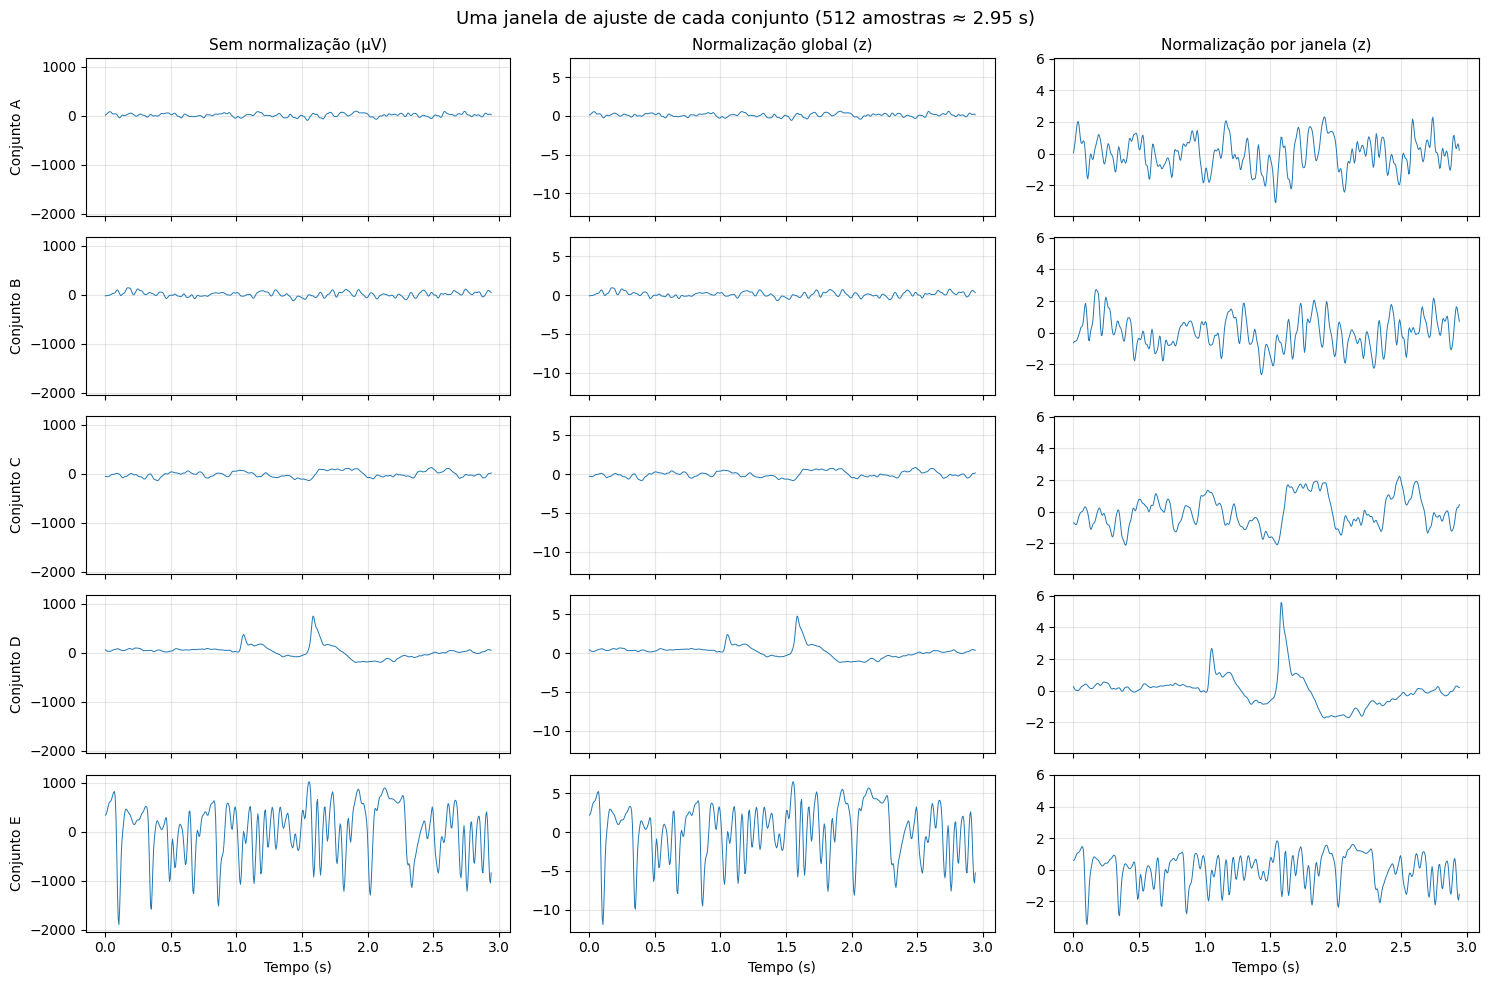

In [94]:
params_global = ajustar_normalizacao(J_fit, "global")
t_jan = np.arange(TAM_JANELA) / freq
versoes = [
    ("Sem normalização (µV)", J_fit),
    ("Normalização global (z)", aplicar_normalizacao(J_fit, params_global, "global")),
    ("Normalização por janela (z)", aplicar_normalizacao(J_fit, {}, "janela")),
]

fig, axes = plt.subplots(5, 3, figsize=(15, 10), sharex=True, sharey="col")
for linha, label in enumerate(CLASSES):
    k = np.flatnonzero(rotulos[id_fit] == label)[0]  # primeira janela de ajuste do conjunto
    for col, (titulo, J) in enumerate(versoes):
        ax = axes[linha, col]
        ax.plot(t_jan, J[k], lw=0.7)
        ax.grid(alpha=0.3)
        if linha == 0:
            ax.set_title(titulo, fontsize=11)
    axes[linha, 0].set_ylabel(f"Conjunto {label}")
for ax in axes[-1]:
    ax.set_xlabel("Tempo (s)")
fig.suptitle(f"Uma janela de ajuste de cada conjunto ({TAM_JANELA} amostras ≈ {TAM_JANELA / freq:.2f} s)", fontsize=13)
plt.tight_layout()
if SALVAR:
    plt.savefig(pasta_fig / "09_janelas_normalizacao.png", dpi=300)
plt.show()

### Dataset e DataLoader

Formato combinado na Ata 2: **(n, canais, amostras)**. Cada item do `JanelasEEG` devolve `(x, y, id_sinal)`:

- `x`: tensor float32 de formato (1, 512) → em lote, **(64, 1, 512)**;
- `y`: inteiro de 0 a 4 (A–E), o formato que a `nn.CrossEntropyLoss` espera;
- `id_sinal`: índice do sinal de origem, para a métrica por sinal.

Como cada rede lê o mesmo lote:

- **CNN 1D** (`nn.Conv1d`): usa `x` direto, (lote, canais, amostras);
- **LSTM** (`nn.LSTM(batch_first=True)`): espera (lote, passos, atributos) → `x.permute(0, 2, 1)` = (64, 512, 1);
- **Transformer**: 512 passos de 1 valor deixam a atenção cara (512² pares) e cada token com pouca informação. Sugestão: agrupar em *patches* de 16 amostras → `x.reshape(lote, 32, 16)` = 32 tokens de 16 valores (ou uma `Conv1d` na entrada fazendo o mesmo papel).

O DataLoader de ajuste embaralha com semente fixa (`SEED`); os de validação e teste não embaralham (ordem fixa, mais fácil de agregar por sinal e de comparar modelos).

In [95]:
class JanelasEEG(Dataset):
    # janelas normalizadas no formato (n, canais, amostras) + rótulo 0–4 + id do sinal de origem
    def __init__(self, janelas, y, id_sinal):
        self.x = torch.from_numpy(np.ascontiguousarray(janelas[:, np.newaxis, :], dtype=np.float32))
        self.y = torch.from_numpy(np.asarray(y, dtype=np.int64))
        self.id_sinal = torch.from_numpy(np.asarray(id_sinal, dtype=np.int64))

    def __len__(self):
        return len(self.y)

    def __getitem__(self, k):
        return self.x[k], self.y[k], self.id_sinal[k]


def preparar_dados(idx_fit, idx_val, idx_teste, tam=TAM_JANELA, passo_fit=PASSO_FIT,
                   passo_aval=PASSO_AVAL, modo=MODO_NORM, batch=BATCH, seed=SEED):
    # pipeline completo da etapa 3 para UMA divisão de sinais inteiros:
    # janela → ajusta a normalização só no ajuste → aplica nos três → DataLoaders
    # idx_val pode ser None (modelo final: ajusta em todo o idx_treino e avalia no teste)
    partes = {"fit": (idx_fit, passo_fit), "val": (idx_val, passo_aval), "teste": (idx_teste, passo_aval)}
    partes = {nome: p for nome, p in partes.items() if p[0] is not None}

    janelas, origem = {}, {}
    for nome, (idx, passo) in partes.items():
        janelas[nome], origem[nome] = janelar(sinais_filtrados, idx, tam, passo)

    params = ajustar_normalizacao(janelas["fit"], modo)

    loaders = {}
    for nome in partes:
        ds = JanelasEEG(aplicar_normalizacao(janelas[nome], params, modo), y_sinal[origem[nome]], origem[nome])
        embaralhar = nome == "fit"
        gerador = torch.Generator().manual_seed(seed) if embaralhar else None
        loaders[nome] = DataLoader(ds, batch_size=batch, shuffle=embaralhar, generator=gerador)
    return loaders, params

Como usar nas próximas fases:

```python
loaders, params = preparar_dados(*folds[0], idx_teste)                 # divisão padrão: 320 / 80 / 100 sinais
for k, (tr, va) in enumerate(folds):                                    # validação cruzada (normalização refeita em cada fold)
    loaders_k, params_k = preparar_dados(tr, va, idx_teste)
loaders_final, params_final = preparar_dados(idx_treino, None, idx_teste)  # modelo final: 400 sinais de ajuste
```

Teste abaixo: um lote passa pelas camadas de entrada das três redes (CNN 1D, LSTM e Transformer), confirmando que o formato serve para todas, e o embaralhamento é reprodutível com a mesma semente.

In [96]:
loaders, params = preparar_dados(idx_fit, idx_val, idx_teste)

x, y, id_lote = next(iter(loaders["fit"]))
print("lote de ajuste → x:", tuple(x.shape), x.dtype, "| y:", tuple(y.shape), y.dtype, "| id_sinal:", tuple(id_lote.shape))
print("janelas por DataLoader:", {nome: len(dl.dataset) for nome, dl in loaders.items()})

# o mesmo lote nas camadas de entrada de cada rede
torch.manual_seed(SEED)
cnn = torch.nn.Conv1d(in_channels=1, out_channels=8, kernel_size=7, padding=3)
lstm = torch.nn.LSTM(input_size=1, hidden_size=16, batch_first=True)
transformer = torch.nn.TransformerEncoderLayer(d_model=16, nhead=4, batch_first=True)
with torch.no_grad():
    saida_cnn = cnn(x)                                # entrada (lote, 1, 512)
    saida_lstm, _ = lstm(x.permute(0, 2, 1))          # entrada (lote, 512, 1)
    saida_tr = transformer(x.reshape(len(x), -1, 16))  # entrada (lote, 32 tokens, 16)
print("saídas → CNN 1D:", tuple(saida_cnn.shape), "| LSTM:", tuple(saida_lstm.shape), "| Transformer:", tuple(saida_tr.shape))

assert x.shape[1:] == (1, TAM_JANELA) and x.dtype == torch.float32, "formato de x errado"
assert y.dtype == torch.int64 and 0 <= int(y.min()) and int(y.max()) <= 4, "rótulos fora de 0–4"
assert torch.equal(y, torch.from_numpy(y_sinal[id_lote.numpy()])), "rótulo não bate com o sinal de origem"

# reprodutibilidade: mesma semente → mesma ordem de embaralhamento
_, _, id_a = next(iter(preparar_dados(idx_fit, idx_val, idx_teste)[0]["fit"]))
_, _, id_b = next(iter(preparar_dados(idx_fit, idx_val, idx_teste)[0]["fit"]))
assert torch.equal(id_a, id_b), "embaralhamento não é reprodutível"
print("\nOK: formato (lote, 1, 512) float32, rótulos 0–4 coerentes com o sinal de origem e embaralhamento reprodutível")

lote de ajuste → x: (64, 1, 512) torch.float32 | y: (64,) torch.int64 | id_sinal: (64,)
janelas por DataLoader: {'fit': 4800, 'val': 640, 'teste': 800}
saídas → CNN 1D: (64, 8, 512) | LSTM: (64, 512, 16) | Transformer: (64, 32, 16)

OK: formato (lote, 1, 512) float32, rótulos 0–4 coerentes com o sinal de origem e embaralhamento reprodutível


### Métrica por sinal

As redes classificam **janelas**, mas o diagnóstico é sobre o **sinal inteiro** (23,6 s). `agregar_por_sinal` tira a média das probabilidades das 8 janelas de cada sinal de validação ou teste e devolve uma previsão por sinal. Assim, todos os modelos podem ser comparados do mesmo jeito, com as duas acurácias: por janela e por sinal.

Teste abaixo com probabilidades **simuladas** (os modelos de verdade vêm na próxima fase): um "modelo" ruidoso que erra parte das janelas, mas acerta mais quando junta as 8 janelas de cada sinal.

In [97]:
def agregar_por_sinal(probs, id_sinal):
    # média das probabilidades das janelas de cada sinal → uma previsão por sinal inteiro
    # probs: (n_janelas, 5), saída softmax do modelo | id_sinal: (n_janelas,)
    # devolve os ids dos sinais (n_sinais,) e as probabilidades médias (n_sinais, 5)
    probs, id_sinal = np.asarray(probs), np.asarray(id_sinal)
    ids_unicos, posicao = np.unique(id_sinal, return_inverse=True)
    soma = np.zeros((len(ids_unicos), probs.shape[1]))
    np.add.at(soma, posicao, probs)
    return ids_unicos, soma / np.bincount(posicao)[:, None]

# teste com um "modelo" simulado e ruidoso
rng = np.random.default_rng(SEED)
id_janelas = loaders["teste"].dataset.id_sinal.numpy()
y_janelas = y_sinal[id_janelas]
probs_sim = rng.dirichlet(np.ones(5), size=len(y_janelas))
probs_sim[np.arange(len(y_janelas)), y_janelas] += 0.2
probs_sim /= probs_sim.sum(axis=1, keepdims=True)

ids_sinais, probs_sinal = agregar_por_sinal(probs_sim, id_janelas)
acc_janela = (probs_sim.argmax(axis=1) == y_janelas).mean()
acc_sinal = (probs_sinal.argmax(axis=1) == y_sinal[ids_sinais]).mean()
print(f"(simulação) acurácia por janela: {acc_janela:.1%} | por sinal: {acc_sinal:.1%} ({len(ids_sinais)} sinais)")

assert len(ids_sinais) == len(idx_teste) and np.allclose(probs_sinal.sum(axis=1), 1), "agregação incorreta"
print("OK: uma previsão por sinal de teste, com probabilidades que somam 1")

(simulação) acurácia por janela: 42.9% | por sinal: 96.0% (100 sinais)
OK: uma previsão por sinal de teste, com probabilidades que somam 1


### Salvando as entregas

Com `SALVAR = True`, grava as janelas já normalizadas da divisão padrão (fold 0), junto com os parâmetros usados (janela, passos, modo e média/desvio da normalização), para a fase de modelagem começar sem refazer nada. No rascunho fica `False`, para não mexer na pasta do grupo.

In [98]:
conteudo = {}
for nome, dl in loaders.items():
    conteudo[f"X_{nome}"] = dl.dataset.x.numpy()
    conteudo[f"y_{nome}"] = dl.dataset.y.numpy()
    conteudo[f"id_sinal_{nome}"] = dl.dataset.id_sinal.numpy()
conteudo.update(
    tam_janela=TAM_JANELA, passo_fit=PASSO_FIT, passo_aval=PASSO_AVAL, modo_norm=MODO_NORM,
    media=params.get("media", np.nan), desvio=params.get("desvio", np.nan),
    fold=FOLD_PADRAO, seed=SEED, classes=CLASSES,
)
for chave in ["X_fit", "X_val", "X_teste"]:
    print(f"{chave}: {conteudo[chave].shape}")

arquivo = pasta_proc / "etapa3_janelas.npz"
if SALVAR:
    np.savez_compressed(arquivo, **conteudo)
    print("salvo em", arquivo.relative_to(pasta_proj.parent), f"({arquivo.stat().st_size / 1e6:.1f} MB)")
else:
    print("\nSALVAR = False → nada foi gravado no drive (rascunho)")

X_fit: (4800, 1, 512)
X_val: (640, 1, 512)
X_teste: (800, 1, 512)

SALVAR = False → nada foi gravado no drive (rascunho)


Para a fase de modelagem, carregar assim (não precisa rodar as etapas anteriores):

```python
d3 = np.load(pasta_proc / "etapa3_janelas.npz")
X_fit, y_fit, id_fit = d3["X_fit"], d3["y_fit"], d3["id_sinal_fit"]          # (4800, 1, 512)
X_val, y_val, id_val = d3["X_val"], d3["y_val"], d3["id_sinal_val"]          # (640, 1, 512)
X_teste, y_teste, id_teste = d3["X_teste"], d3["y_teste"], d3["id_sinal_teste"]  # (800, 1, 512)
```

- **Validação cruzada** ou **outra janela/normalização**: usar `preparar_dados` direto (as células desta etapa precisam ter sido rodadas).
- **Métrica**: reportar acurácia, precisão, recall, F1 e matriz de confusão por janela e, com `agregar_por_sinal`, por sinal.
- **Teste**: usado uma única vez, no final (regra da etapa 2).

Pontos para decidir com o grupo:

- tamanho da janela (512 ≈ 3 s; vale testar 256 ≈ 1,5 s e 1024 ≈ 5,9 s);
- normalização global × por janela (ou comparar as duas no mesmo modelo);
- métrica principal do relatório: por janela ou por sinal.